# 05 · Walk-forward en vivo: A vs B vs C

**Responsabilidad:** ejecutar el experimento completo en memoria y verificar que reproduce **exactamente** los resultados versionados en `results/`. Este notebook **no escribe archivos** ni usa MLflow.

En cada ventana *k* (Figura 3 del notebook 00):
1. Cada grupo predice con su modelo vigente y se calculan Precision, Recall y F1.
2. Se evalúan los dos disparadores (notebook 04).
3. Si corresponde, se reentrena con los **últimos 252 días**, sin el último día de la ventana (purga, D8).
4. La versión nueva rige **desde la ventana siguiente**.

In [1]:
import os, pathlib, warnings
warnings.filterwarnings("ignore")
root = pathlib.Path.cwd()
while not (root / "pyproject.toml").exists():
    root = root.parent
os.chdir(root)  # todas las rutas del proyecto son relativas a la raíz

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from msft_mlops.config import load_config
from msft_mlops.data import load_raw
from msft_mlops.features import build_dataset

pd.set_option("display.precision", 3)
plt.rcParams.update({"figure.figsize": (10, 4), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "lines.linewidth": 2})
# Paleta validada (dataviz): A azul, B naranja, C aqua; baselines y neutros en gris.
COLOR = {"A": "#2a78d6", "B": "#eb6834", "C": "#1baf7a"}
MARKER = {"A": "o", "B": "s", "C": "^"}
GRIS = "#8a8a85"

cfg = load_config()
f = cfg["features"]
FEAT_KW = dict(n_lags=f["n_lags"], ma_windows=tuple(f["ma_windows"]), vol_ma_window=f["vol_ma_window"])
raw = load_raw(cfg)              # falla si el SHA-256 no coincide con config/experiment.toml
ds = build_dataset(raw, **FEAT_KW)
FEATS = [c for c in ds.columns if c != "y"]
print(f"raw: {len(raw)} filas | dataset modelable: {len(ds)} filas, {len(FEATS)} features")

raw: 1254 filas | dataset modelable: 1234 filas, 9 features


In [2]:
import time
from msft_mlops.walk_forward import run_replica
t0 = time.time()
live = {}
for r in cfg.replicas:
    live[r] = run_replica(r, ds, cfg)
    print(f"{r}: listo ({time.time() - t0:.0f} s acumulados)")
wm_live = pd.concat([live[r]["window_metrics"] for r in cfg.replicas], ignore_index=True)
mv_live = pd.concat([live[r]["model_versions"] for r in cfg.replicas], ignore_index=True)

logreg: listo (8 s acumulados)


rf: listo (22 s acumulados)


## 1. Qué decidió el monitoreo de B en cada ventana

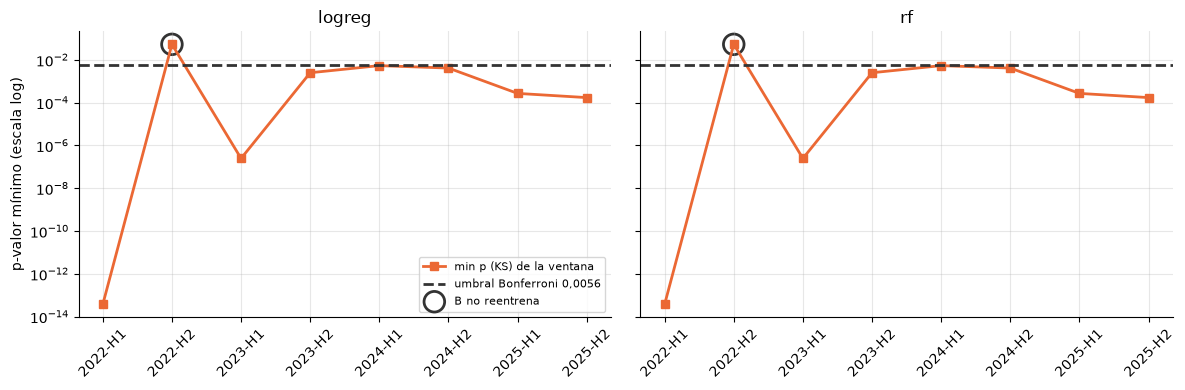

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, r in zip(axes, cfg.replicas):
    b = wm_live[(wm_live.replica == r) & (wm_live.group == "B")]
    ax.plot(b.window_id, b.drift_min_p.astype(float).clip(lower=1e-16), marker="s", color=COLOR["B"], label="min p (KS) de la ventana")
    ax.axhline(b.drift_threshold.astype(float).iloc[0], color="#333", ls="--", label="umbral Bonferroni 0,0056")
    no = b.retrain_reason.fillna("") == ""
    ax.scatter(b.window_id[no], b.drift_min_p.astype(float)[no], s=220, facecolors="none", edgecolors="#333", lw=2, label="B no reentrena")
    ax.set_yscale("log"); ax.set_title(r); ax.tick_params(axis="x", rotation=45)
axes[0].set_ylabel("p-valor mínimo (escala log)"); axes[0].legend(fontsize=8); plt.tight_layout()

**Cómo leerlo:** cada punto es el p-valor más chico de las 9 features en esa ventana (escala logarítmica). Debajo de la línea punteada hay deriva. El círculo marca la ventana en que B no reentrenó.

**Qué concluimos:** Solo **2022-H2** queda por encima del umbral, en ambas réplicas. Es la única ventana en que B no reentrena. En 2025-H1 (LR) coinciden deriva y caída de F1.

## 2. F1 de cada grupo, calculado en vivo

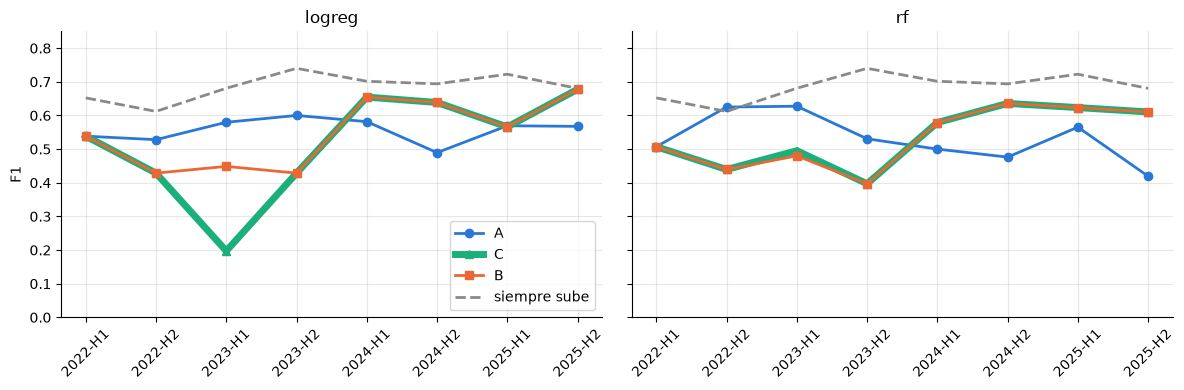

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, r in zip(axes, cfg.replicas):
    sub = wm_live[wm_live.replica == r]
    for g, lw in [("A", 2), ("C", 5), ("B", 2)]:
        s = sub[sub.group == g]; ax.plot(s.window_id, s.f1, marker=MARKER[g], color=COLOR[g], lw=lw, label=g)
    s = sub[sub.group == "siempre_sube"]; ax.plot(s.window_id, s.f1, ls="--", color=GRIS, label="siempre sube")
    ax.set_title(r); ax.tick_params(axis="x", rotation=45); ax.set_ylim(0, 0.85)
axes[0].legend(); axes[0].set_ylabel("F1"); plt.tight_layout()

**Cómo leerlo:** cada línea es un grupo y la gris punteada el baseline "siempre sube". Donde B = C, la línea naranja va encima de la verde.

**Qué concluimos:** B y C coinciden casi siempre, porque B reentrenó en 7 de 8 ventanas. Ninguno supera al baseline trivial. El análisis completo está en el notebook 06.

## 3. Verificación de reproducibilidad contra `results/`

In [5]:
ref_wm = pd.read_csv("results/window_metrics.csv")
ref_mv = pd.read_csv("results/model_versions.csv")
assert len(ref_wm) == len(wm_live) and len(ref_mv) == len(mv_live)
for c in ["precision", "recall", "f1", "n"]:
    np.testing.assert_allclose(wm_live[c].astype(float), ref_wm[c].astype(float), equal_nan=True, err_msg=c)
assert (wm_live.retrain_reason.fillna("") == ref_wm.retrain_reason.fillna("")).all()
for c in ["f1_ref", "sigma", "n_train"]:
    np.testing.assert_allclose(mv_live[c].astype(float), ref_mv[c].astype(float), err_msg=c)
print(f"OK: {len(wm_live)} métricas por ventana y {len(mv_live)} versiones de modelo idénticas a results/")
mv_live[mv_live.version > 1].groupby(['replica', 'group', 'reason']).size().unstack(fill_value=0)

OK: 96 métricas por ventana y 36 versiones de modelo idénticas a results/


reason         deriva  deriva+caida_f1  periodico
replica group                                    
logreg  B           6                1          0
        C           0                0          8
rf      B           7                0          0
        C           0                0          8

**Qué concluimos:** re-ejecutar el experimento produce exactamente los mismos números que están versionados en el repositorio. Los resultados del informe son **reproducibles** (criterio SC-003).